# 03 Coronagraph and contrast

Three parameters set the coronagraph's contribution to the noise budget:

- `raw_dh_contrast`, the raw dark-hole contrast. It sets the residual speckle rate, `speckle = host x contrast x EE` (notebook 01).
- `ppgain`, the post-processing gain. Speckles that survive post-processing form a systematic floor `M = speckle / ppgain` that grows linearly with time, unlike photon noise. `ppgain` is a number you supply, not something the calculator predicts, and it carries no random-noise cost of its own.
- `separation`, the planet's angular distance from the star in arcsec. It sets the off-axis throughput of the focal-plane mask.

Because `M` grows like t while photon noise grows like sqrt(t), the SNR curve flattens into a plateau at `source / M`. With the default scene the planet and speckle rates are equal, so the plateau sits at SNR = ppgain = 10. 
> Requirements: an editable install (`pip install -e .`), as in notebook 01.

In [1]:
import astropy.units as u
from esc_etc import Simulation, use_lazuli_style
use_lazuli_style()

sim = Simulation.from_default(hoststarmag=-0.353, planetdeltamag=20,
                              contrast=1e-8, ppgain=10, separation=0.4)

## 1. Raw dark-hole contrast

`plot_snr_vs_time(sweep=...)` draws one SNR curve per value of any parameter you could pass to `update()`, and restores the original value afterwards. Better contrast lowers the speckle rate and therefore raises the plateau: at 1e-9 the ceiling is 100, at 1e-7 it is 1, and no integration time gets past it.

contrast 1e-07: SNR(1 h) = 0.999


contrast 1e-08: SNR(1 h) = 9.874


contrast 1e-09: SNR(1 h) = 62.561


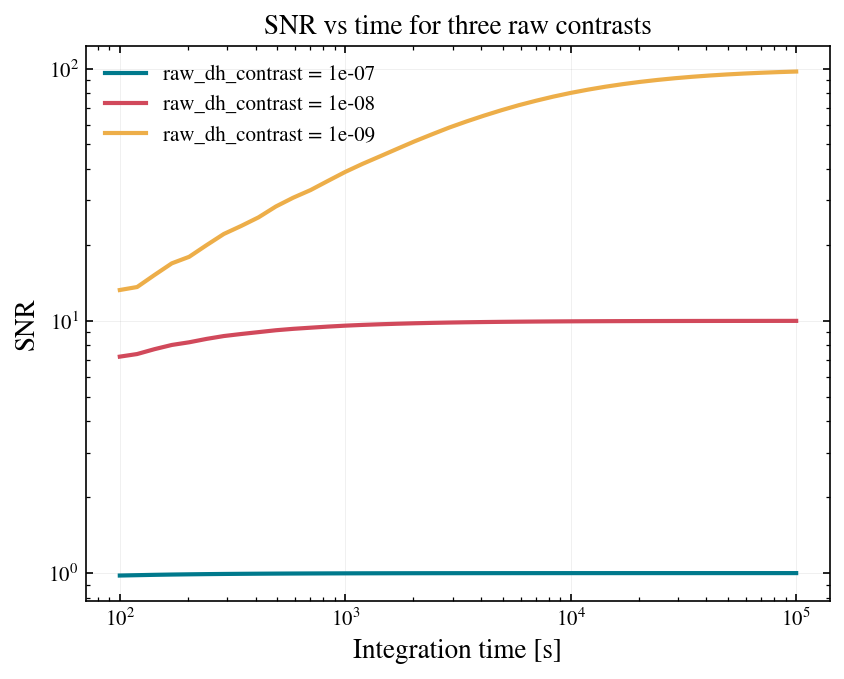

In [2]:
fig, ax = sim.plot_snr_vs_time(sweep={'coronagraph__raw_dh_contrast': [1e-7, 1e-8, 1e-9]})
ax.set_title('SNR vs time for three raw contrasts');

snr_at_1h = {}
for cval in [1e-7, 1e-8, 1e-9]:
    sim.update(coronagraph__raw_dh_contrast=cval)
    snr_at_1h[cval] = sim.get_snr(3600, 100)['snr']
    print(f'contrast {cval:.0e}: SNR(1 h) = {snr_at_1h[cval]:.3f}')
sim.reset()
assert snr_at_1h[1e-7] < snr_at_1h[1e-8] < snr_at_1h[1e-9]
assert snr_at_1h[1e-7] < 1.0 + 1e-6      # pinned at the plateau

## 2. Post-processing gain

`ppgain` moves the plateau without changing the photon-limited rise. At ppgain 1 the floor equals the speckle rate itself and the SNR never exceeds 1 for this scene.

ppgain   1: SNR(1 h) = 1.000


ppgain  10: SNR(1 h) = 9.874


ppgain 100: SNR(1 h) = 52.975


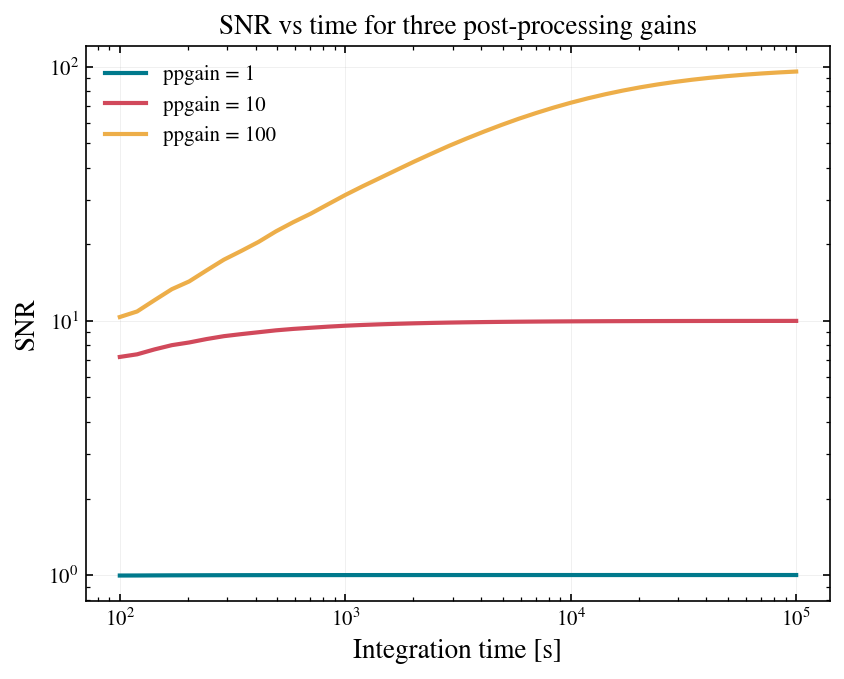

In [3]:
fig, ax = sim.plot_snr_vs_time(sweep={'coronagraph__ppgain': [1, 10, 100]})
ax.set_title('SNR vs time for three post-processing gains');

for g in [1, 10, 100]:
    sim.update(coronagraph__ppgain=g)
    print(f'ppgain {g:3d}: SNR(1 h) = {sim.get_snr(3600, 100)["snr"]:.3f}')
sim.reset()

## 3. Separation and off-axis throughput

The focal-plane mask attenuates the planet as well as the star. `off_axis_throughput` is the fraction of planet light transmitted at a given separation; it rises from near zero inside the inner working angle toward a plateau. The throughput multiplies every rate in the aperture, so moving the planet in or out changes the photon-limited part of the curve but not the plateau, which is a ratio of two rates with the same factor.

separation 0.1 arcsec: off-axis throughput 0.166
separation 0.2 arcsec: off-axis throughput 0.425
separation 0.4 arcsec: off-axis throughput 0.580


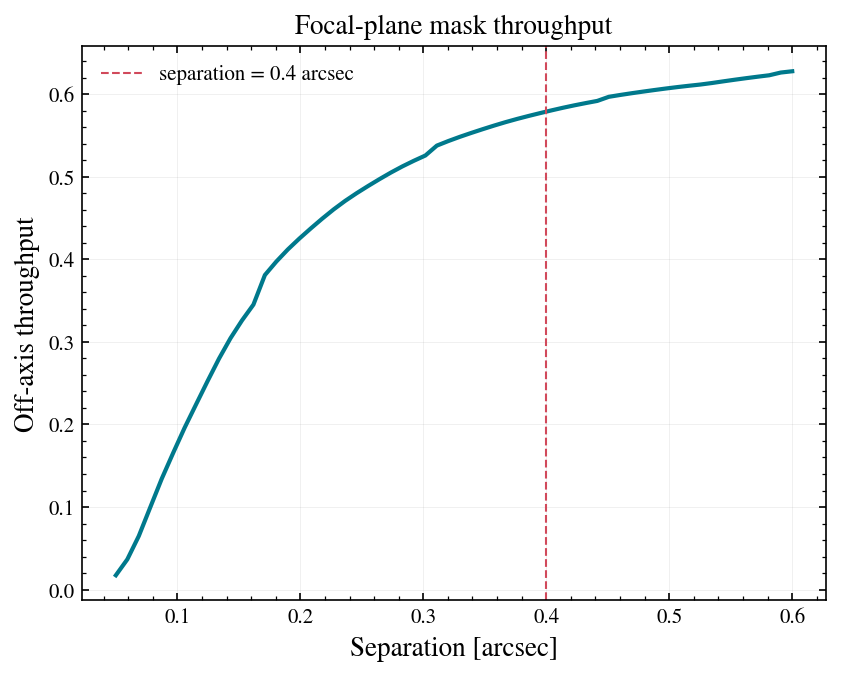

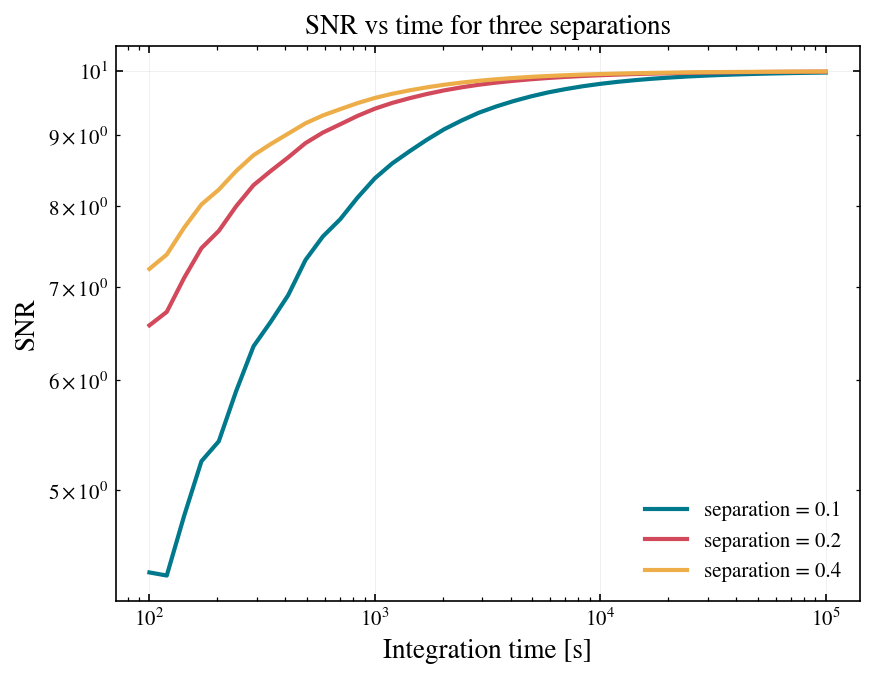

In [4]:
for sep in [0.1, 0.2, 0.4]:
    print(f'separation {sep} arcsec: off-axis throughput {sim.coronagraph.off_axis_throughput(sep):.3f}')
assert abs(sim.coronagraph.off_axis_throughput(0.4) - 0.58) < 0.01

fig, ax = sim.coronagraph.plot_offaxis_throughput()
ax.set_title('Focal-plane mask throughput');

fig, ax = sim.plot_snr_vs_time(sweep={'coronagraph__separation': [0.1, 0.2, 0.4]})
ax.set_title('SNR vs time for three separations');

## 4. Reference-star subtraction

With `subtraction="rdi"` a reference star `ref_brightness_ratio` times brighter than the host is observed for `ref_time_ratio` times the science time and subtracted. Its photon noise adds to the budget and the reference time is charged, so `charged_time` is larger than `science_time`. The defaults are `ref_brightness_ratio=1` and `ref_time_ratio=1`, so one hour of science is charged as two. Roll or ADI self-subtraction is not modelled.

In [5]:
sim.update(coronagraph__subtraction='rdi')
out = sim.get_snr(3600, 100)
print('SNR with RDI   :', round(out['snr'], 3))
print('science time   :', out['science_time'], '| charged time:', out['charged_time'])
sim.reset()

SNR with RDI   : 9.806
science time   : 3600.0 s | charged time: 7200.0 s


Notebook 04 covers the time axis in more detail: frame times, read noise, and saturation.